# cycleVI on the RNA of the CRISPR screen

[CycleVI](https://doi.org/10.1101/2025.11.04.686009) learns a circular position in the cell cycle for each cell, plus an embedding with the cell cycle removed. We ran it on the raw RNA counts of all QC-passing cells. This notebook first checks the inferred position against same-cell imaging, which the model never saw. It then uses the knockouts as readouts along the cycle. They can't serve as anchors because the library has no cell cycle regulators.

**Preliminary:** these results come from a 100-epoch cycleVI model, whose loss was still falling. A 400-epoch run will replace them.


In [1]:
from pathlib import Path

import anndata as ad
import mantispy as mt
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold, cross_val_predict, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

DATA, RESULTS = Path("data"), Path("cyclevi")
RUN = "nobatch"

img = ad.read_h5ad(DATA / "imaging.h5ad")
img = img[~img.obs["qc_fail"].values].copy()
rna = ad.read_h5ad(DATA / "rna.h5ad")
rna = rna[~rna.obs["qc_fail"].values].copy()
rna.layers.clear()
angle_raw = pd.read_csv(RESULTS / f"{RUN}_angles.csv", index_col=0)["cycle_angle"]
z_cycle = pd.read_csv(RESULTS / f"{RUN}_cycle.csv", index_col=0)
z_other = pd.read_csv(RESULTS / f"{RUN}_other.csv", index_col=0)
assert (angle_raw.index == rna.obs_names).all() and (rna.obs_names == img.obs_names).all()
detected = np.asarray((rna.X > 0).mean(0)).ravel()
rna.obs["log_counts"] = np.log1p(rna.obs["rna_total_counts"])
sc.pp.normalize_total(rna, target_sum=1e4)
sc.pp.log1p(rna)
wells = rna.obs["Well"].astype(str).values
rna.shape

(206091, 54949)

## Is the position a circle, and is it stable?

A usable position needs cells arranged around a ring with no gap at the centre being filled, and it should agree between runs. We compare runs with the circular correlation, which ignores where the angle starts.

Radius quantiles (5, 25, 50, 75, 95%): [0.423, 0.766, 1.115, 1.57, 2.448]
Circular correlation with other runs: {'well': 0.517}


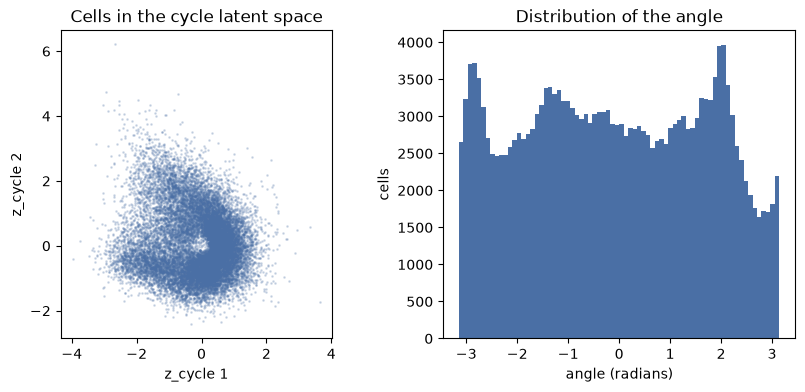

In [2]:
def circular_corr(a, b):
    sa, sb = np.sin(a - stats.circmean(a, high=np.pi, low=-np.pi)), np.sin(b - stats.circmean(b, high=np.pi, low=-np.pi))
    return (sa * sb).sum() / np.sqrt((sa**2).sum() * (sb**2).sum())


radius = np.hypot(z_cycle.iloc[:, 0], z_cycle.iloc[:, 1])
print("Radius quantiles (5, 25, 50, 75, 95%):", radius.quantile([0.05, 0.25, 0.5, 0.75, 0.95]).round(3).tolist())
stability = {}
for other_run in ["nobatch", "well", "nobatch400"]:
    path = RESULTS / f"{other_run}_angles.csv"
    if path.exists() and other_run != RUN:
        stability[other_run] = round(float(circular_corr(angle_raw.values, pd.read_csv(path, index_col=0)["cycle_angle"].values)), 3)
print("Circular correlation with other runs:", stability)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sample = np.random.default_rng(0).choice(len(z_cycle), 20000, replace=False)
axes[0].scatter(z_cycle.iloc[sample, 0], z_cycle.iloc[sample, 1], s=1, alpha=0.2, color="#4a6fa5")
axes[0].set(xlabel="z_cycle 1", ylabel="z_cycle 2", title="Cells in the cycle latent space", aspect="equal")
axes[1].hist(angle_raw, bins=72, color="#4a6fa5")
axes[1].set(xlabel="angle (radians)", ylabel="cells", title="Distribution of the angle")
plt.show()

## Fixing the start and direction with marker genes

The angle has no fixed start or direction. We set position 0 at the peak of the S score and choose the direction that reaches the G2/M peak by the shorter arc. The model was initialised from these same markers, so this step says nothing about whether the position is correct. The checks after it use data that the model didn't see.

In [3]:
S_GENES = """MCM5 PCNA TYMS FEN1 MCM2 MCM4 RRM1 UNG GINS2 MCM6 CDCA7 DTL PRIM1 UHRF1 CENPU HELLS RFC2 RPA2 NASP
RAD51AP1 GMNN WDR76 SLBP CCNE2 UBR7 POLD3 MSH2 ATAD2 RAD51 RRM2 CDC45 CDC6 EXO1 TIPIN DSCC1 BLM CASP8AP2 USP1
CLSPN POLA1 CHAF1B BRIP1 E2F8""".split()
G2M_GENES = """HMGB2 CDK1 NUSAP1 UBE2C BIRC5 TPX2 TOP2A NDC80 CKS2 NUF2 CKS1B MKI67 TMPO CENPF TACC3 PIMREG SMC4 CCNB2
CKAP2L CKAP2 AURKB BUB1 KIF11 ANP32E TUBB4B GTSE1 KIF20B HJURP CDCA3 JPT1 CDC20 TTK CDC25C KIF2C RANGAP1 NCAPD2
DLGAP5 CDCA2 CDCA8 ECT2 KIF23 HMMR AURKA PSRC1 ANLN LBR CKAP5 CENPE CTCF NEK2 G2E3 GAS2L3 CBX5 CENPA""".split()
sc.tl.score_genes_cell_cycle(rna, s_genes=[g for g in S_GENES if g in rna.var_names], g2m_genes=[g for g in G2M_GENES if g in rna.var_names], random_state=0)
obs = rna.obs


def harmonic_peak(values, theta):
    v = np.asarray(values, dtype=float) - np.mean(values)
    z = (v * np.exp(1j * theta)).mean()
    return float(np.angle(z)), float(2 * np.abs(z))


theta = angle_raw.values
peak_s, _ = harmonic_peak(obs["S_score"], theta)
peak_g2m, _ = harmonic_peak(obs["G2M_score"], theta)
gap = (peak_g2m - peak_s + np.pi) % (2 * np.pi) - np.pi
direction = np.sign(gap)
position = (direction * (theta - peak_s)) % (2 * np.pi)
obs["cycle_position"] = position
print(f"G2M peak is {abs(gap):.2f} radians ({abs(gap) / (2 * np.pi):.1%} of the cycle) after the S peak")

raw = pd.DataFrame(img.layers["raw"], index=img.obs_names, columns=img.var_names)
dna_raw = ((raw["Nucleus_Nuclear"] - raw["Bkg_Nucleus_Nuclear"]) * raw["NuclearArea"]).clip(lower=1)
obs["dna"] = (np.log2(dna_raw) - np.log2(dna_raw).groupby(wells).transform("median")).values
obs["nuclear_area"], obs["cell_area"] = raw["NuclearArea"].values, raw["Area"].values
bins = pd.cut(position, np.linspace(0, 2 * np.pi, 13), include_lowest=True, labels=[f"{i * 30}-{(i + 1) * 30}" for i in range(12)])
table = obs.groupby(bins, observed=True).agg(cells=("dna", "size"), S=("S_score", "median"), G2M=("G2M_score", "median"), dna=("dna", "median"), nuclear_area=("nuclear_area", "median"), cell_area=("cell_area", "median"), log_counts=("log_counts", "median"))
table.index.name = "position (degrees, 0 = S peak)"
table.round(3)

G2M peak is 1.55 radians (24.7% of the cycle) after the S peak


,cells,S,G2M,dna,nuclear_area,cell_area,log_counts
"position (degrees, 0 = S peak)",,,,,,,
0-30,17128,0.195,0.140,-0.028,841.0,3831.0,7.336
30-60,16438,0.159,0.199,0.085,861.5,3869.5,7.352
60-90,17089,0.119,0.268,0.285,901.0,4013.0,7.398
90-120,18720,0.054,0.334,0.455,944.0,4297.0,7.467
120-150,19845,-0.029,0.276,0.339,889.0,3730.0,7.323
150-180,11104,-0.056,0.123,-0.126,752.0,2964.5,7.086
180-210,16625,-0.081,0.009,-0.162,803.0,3405.0,7.185
210-240,17205,-0.030,-0.029,-0.158,816.0,3682.0,7.250
240-270,15883,0.042,-0.009,-0.195,789.0,3405.0,7.203


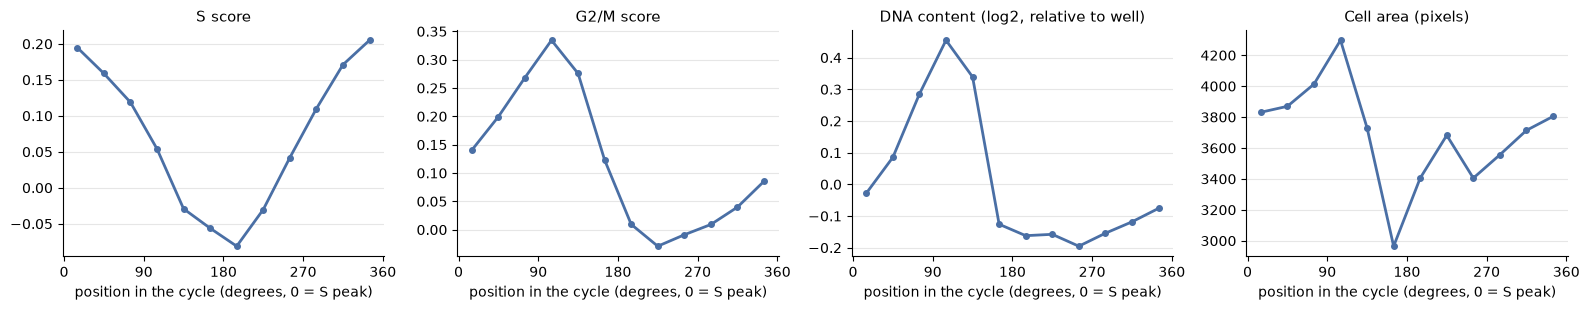

In [4]:
centres = np.radians(np.arange(15, 360, 30))
panels = {"S score": table["S"], "G2/M score": table["G2M"], "DNA content (log2, relative to well)": table["dna"], "Cell area (pixels)": table["cell_area"]}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2), sharex=True)
for ax, (title, values) in zip(axes, panels.items()):
    ax.plot(np.degrees(centres), values.values, color="#4a6fa5", lw=2, marker="o", ms=4)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("position in the cycle (degrees, 0 = S peak)")
    ax.set_xticks(range(0, 361, 90))
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="0.9", lw=0.8)
fig.tight_layout()
plt.show()

## Is the position right? Tests on data the model didn't see

We use three tests. First, cell cycle genes outside the marker lists should peak in the known order, with G1/S genes before G2/M genes. Second, DNA content and nuclear area should rise and fall along the position. Third, we compare how much of the imaging signal the position explains with how much the two marker scores explain, within wells, and with shuffled positions as a null.

In [5]:
HELD_OUT = {"G1/S": ["CCNE1", "E2F1", "CDT1", "MCM3", "MCM7", "MCM10", "CDC25A", "CHEK1"], "G2/M": ["CCNA2", "CCNB1", "PLK1", "CDC25B", "KIF20A", "PTTG1", "KPNA2"]}
rows = []
for stage, genes in HELD_OUT.items():
    for gene in genes:
        if gene not in rna.var_names or gene in S_GENES + G2M_GENES:
            continue
        values = np.asarray(rna[:, gene].X.todense()).ravel()
        peak, amplitude = harmonic_peak(values, position)
        rows.append({"stage": stage, "gene": gene, "share of cells detecting": (values > 0).mean(), "peak (degrees)": np.degrees(peak) % 360, "amplitude (log expression)": amplitude})
pd.DataFrame(rows).round(3)

,stage,gene,share of cells detecting,peak (degrees),amplitude (log expression)
0,G1/S,CCNE1,0.055,307.942,0.051
1,G1/S,E2F1,0.098,332.624,0.120
2,G1/S,CDT1,0.104,345.666,0.088
3,G1/S,MCM3,0.204,340.102,0.159
4,G1/S,MCM7,0.421,12.659,0.242
5,G1/S,MCM10,0.060,343.472,0.067
6,G1/S,CDC25A,0.024,342.982,0.021
7,G1/S,CHEK1,0.050,9.564,0.026
8,G2/M,CCNA2,0.072,85.759,0.098
9,G2/M,CCNB1,0.232,101.924,0.379


In [6]:
def design(position):
    return np.column_stack([np.ones(len(position)), np.sin(position), np.cos(position), np.sin(2 * position), np.cos(2 * position)])


def r2(y, x):
    y = pd.Series(np.asarray(y, dtype=float))
    y = (y - y.groupby(wells).transform("mean")).to_numpy()
    fit = x @ np.linalg.lstsq(x, y, rcond=None)[0]
    return 1 - ((y - fit) ** 2).sum() / ((y - y.mean()) ** 2).sum()


scores = np.column_stack([np.ones(len(obs)), obs["S_score"], obs["G2M_score"]])
shuffled = np.random.default_rng(0).permutation(position)
targets = {"DNA content": obs["dna"], "nuclear area": obs["nuclear_area"], "cell area": obs["cell_area"], "log counts": obs["log_counts"]}
for channel in ["Phospho-p38", "Phospho-HSP27", "Phospho-ERK1_Phospho-ERK2", "ERK1_ERK2", "Actin", "Mitochondria", "Cell-Membrane"]:
    targets[f"{channel} intensity"] = raw[channel].values
pd.DataFrame({name: {"position": r2(y, design(position)), "S and G2M scores": r2(y, scores), "shuffled position": r2(y, design(shuffled))} for name, y in targets.items()}).T.round(4)

,position,S and G2M scores,shuffled position
DNA content,0.0831,0.1069,0.0
nuclear area,0.0117,0.0294,0.0
cell area,0.0149,0.0541,0.0
log counts,0.0281,0.0826,0.0
Phospho-p38 intensity,0.0488,0.0286,0.0
Phospho-HSP27 intensity,0.0037,0.0036,0.0
Phospho-ERK1_Phospho-ERK2 intensity,0.0335,0.0198,0.0
ERK1_ERK2 intensity,0.0150,0.0178,0.0
Actin intensity,0.0072,0.0124,0.0
Mitochondria intensity,0.0110,0.0150,0.0


Imaging can also predict the position directly. We predict the sine and cosine of the position from all selected imaging features on wells the model hasn't seen, and compare the result with the position from RNA.

In [7]:
x = np.nan_to_num(np.clip(np.asarray(img.X), -10, 10))
channel, modality, selected = img.var["channel"].astype(str).values, img.var["modality"].astype(str).values, img.var["selected"].values
predicted = cross_val_predict(make_pipeline(StandardScaler(), Ridge(10)), x[:, selected], np.column_stack([np.sin(position), np.cos(position)]), cv=GroupKFold(6), groups=wells)
image_position = np.arctan2(predicted[:, 0], predicted[:, 1]) % (2 * np.pi)
error = np.abs((image_position - position + np.pi) % (2 * np.pi) - np.pi)
{"circular correlation with RNA position": round(float(circular_corr(image_position, position)), 3), "median error (degrees, 90 = chance)": round(float(np.degrees(np.median(error))), 1)}

{'circular correlation with RNA position': 0.449,
 'median error (degrees, 90 = chance)': 49.6}

## Does the cycle-free embedding remove the cycle and keep the biology?

We compare cycleVI's `z_other` with a PCA of the same RNA counts on 100,000 cells. `mt.metrics.batch_variance_explained` shows what each embedding contains. kNN, `mt.tl.map` and `mt.tl.edistance` show whether knockouts still separate from non-targeting cells.

In [8]:
index = np.sort(np.random.default_rng(0).choice(rna.n_obs, 100_000, replace=False))
common = detected >= 0.01
hvg = sc.pp.highly_variable_genes(rna[:, common], n_top_genes=2000, inplace=False)["highly_variable"].values
hvg_names = rna.var_names[common][hvg]
pcs = PCA(30, random_state=0).fit_transform(np.clip(StandardScaler().fit_transform(rna[index, hvg_names].X.toarray()), -10, 10))
shared = obs.iloc[index].copy()
shared["Metadata_Plate"] = "Cytos-MPS_TNFa"
shared["Metadata_Well"] = shared["Well"].astype(str)
shared["Metadata_Guide"] = shared["guide"].astype(str)
shared["Metadata_Perturbation"] = shared["target_gene"].astype(str)
shared["Metadata_Condition"] = shared["condition"].astype(str)
shared["Metadata_ImageID"] = shared["Well"].astype(str) + "_" + shared["tile_id"].astype(str)
shared["Metadata_ObjectType"] = "cell"
shared["Metadata_ObjectNumber"] = shared["Cell"].astype(int)
shared["position_sin"], shared["position_cos"] = np.sin(shared["cycle_position"]), np.cos(shared["cycle_position"])
views = {"RNA PCA": pcs, "cycleVI z_other": z_other.to_numpy()[index], "cycleVI z_cycle": z_cycle.to_numpy()[index]}


def view(values):
    a = ad.AnnData(X=np.asarray(values, dtype=np.float32), obs=shared.copy())
    a.obsm["X_pca"] = np.asarray(values, dtype=np.float32)
    return a


KEYS = ["position_sin", "position_cos", "S_score", "G2M_score", "dna", "Well", "condition", "target_gene", "log_counts"]
pd.DataFrame({name: mt.metrics.batch_variance_explained(view(v), KEYS).set_index("key")["value"] for name, v in views.items()}).T.round(4)

key,position_sin,position_cos,S_score,G2M_score,dna,Well,condition,target_gene,log_counts
RNA PCA,0.0280,0.0102,0.0111,0.0376,0.0250,0.0305,0.0269,0.0118,0.1071
cycleVI z_other,0.0004,0.0009,0.0012,0.0015,0.0111,0.0149,0.0067,0.0221,0.0297
cycleVI z_cycle,0.4020,0.4120,0.3640,0.3847,0.0391,0.0008,0.0002,0.0005,0.0111


## Latent spaces coloured by the position

Each panel shows 30,000 cells. The top row is coloured by the cycle position from RNA, with a colour map that wraps around because 0 and 360 degrees are the same point. The bottom row is coloured by DNA content, which the model never saw. If a space contains the cycle, cells of similar colour sit together.

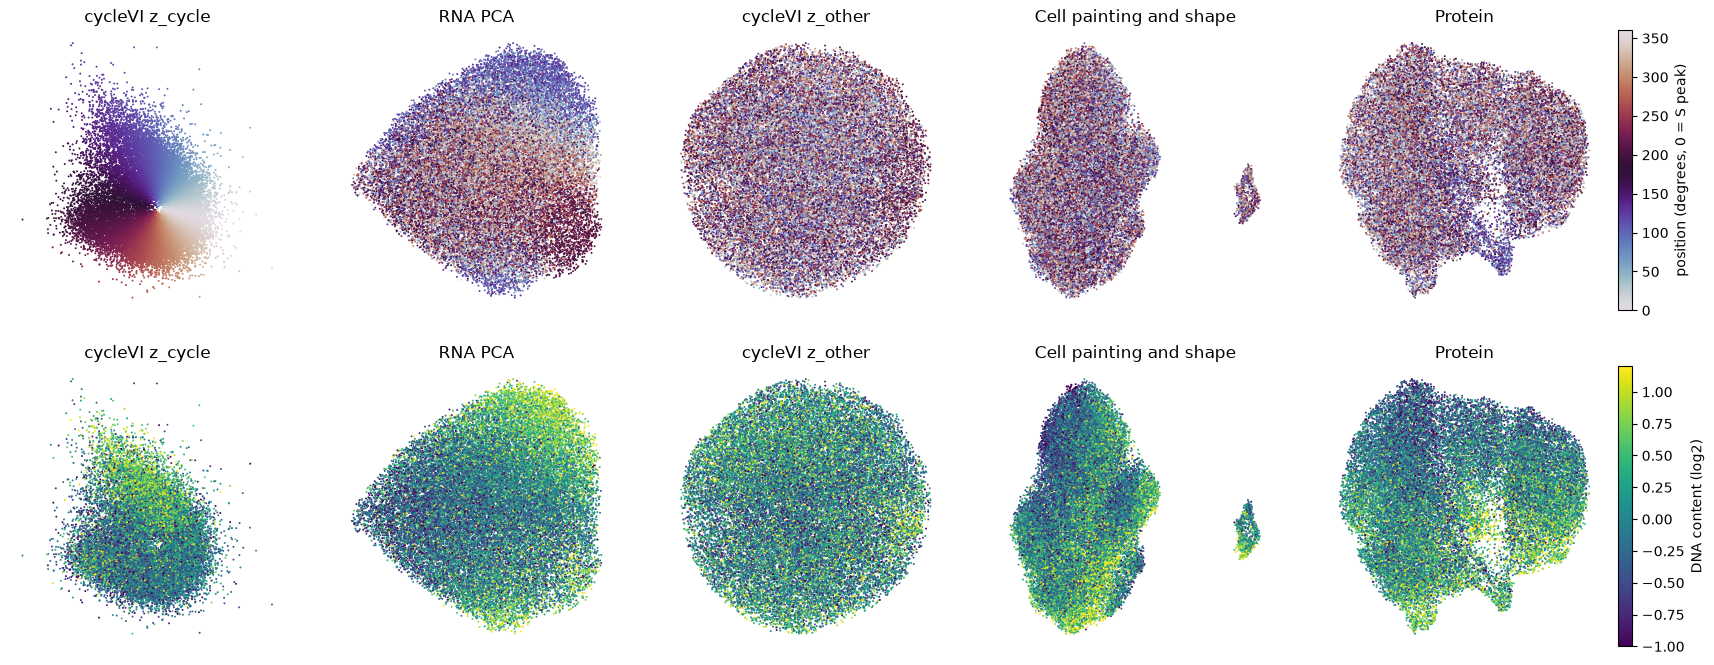

In [9]:
Path("figures").mkdir(exist_ok=True)
sub = np.sort(np.random.default_rng(0).choice(len(index), 30_000, replace=False))
paint_view = PCA(30, random_state=0).fit_transform(x[index][:, selected & np.isin(modality, ["cell_paint", "shape"])])
protein_view = PCA(10, random_state=0).fit_transform(x[index][:, selected & (modality == "protein")])
embeddings = {"RNA PCA": views["RNA PCA"], "cycleVI z_other": views["cycleVI z_other"], "Cell painting and shape": paint_view, "Protein": protein_view}
layout = {"cycleVI z_cycle": views["cycleVI z_cycle"][sub]}
for name, values in embeddings.items():
    a = ad.AnnData(obs=pd.DataFrame(index=[str(i) for i in sub]), obsm={"X_use": np.asarray(values[sub], dtype=np.float32)})
    sc.pp.neighbors(a, use_rep="X_use", transformer="sklearn")
    sc.tl.umap(a, random_state=0)
    layout[name] = a.obsm["X_umap"]
colours = {"position": (np.degrees(shared["cycle_position"].values[sub]), "twilight", 0, 360), "DNA content": (shared["dna"].values[sub], "viridis", -1, 1.2)}
fig, axes = plt.subplots(2, 5, figsize=(21, 8))
for row, (label, (values, cmap, low, high)) in zip(axes, colours.items()):
    for ax, (name, xy) in zip(row, layout.items()):
        order = np.random.default_rng(1).permutation(len(xy))
        points = ax.scatter(xy[order, 0], xy[order, 1], c=values[order], cmap=cmap, vmin=low, vmax=high, s=2, linewidths=0, rasterized=True)
        ax.set(title=name, xticks=[], yticks=[])
        ax.spines[["top", "right", "left", "bottom"]].set_visible(False)
    fig.colorbar(points, ax=row, fraction=0.012, pad=0.01, label="position (degrees, 0 = S peak)" if label == "position" else "DNA content (log2)")
fig.savefig("figures/latent_spaces.png", dpi=130, bbox_inches="tight")
plt.show()

## Which genes and morphology features follow the position?

For every gene and imaging feature, we fit a sine and cosine of the position within each well on 100,000 cells. `r2` is the variance the position explains. `r2_given_size` is the variance it explains after cell area and RNA depth are accounted for, which matters because many features simply scale with cell size. `peak` is the position where the feature is highest. The full tables are written as CSV.

In [10]:
D = np.column_stack([np.sin(shared["cycle_position"]), np.cos(shared["cycle_position"]), np.sin(2 * shared["cycle_position"]), np.cos(2 * shared["cycle_position"])])
size = np.column_stack([np.log(shared["cell_area"]), shared["log_counts"]])
groups_index = shared["Well"].astype(str).values


def centre(values):
    frame = pd.DataFrame(values)
    return (frame - frame.groupby(groups_index).transform("mean")).to_numpy(np.float64)


def explained(y, x_block):
    beta = np.linalg.lstsq(x_block, y, rcond=None)[0]
    return ((x_block @ beta) ** 2).sum(0) / np.maximum((y**2).sum(0), 1e-12)


D_c, size_c = centre(D), centre(size)
residual_design = D_c - size_c @ np.linalg.lstsq(size_c, D_c, rcond=None)[0]


def rank_features(values, names, extra):
    y = centre(values)
    residual_y = y - size_c @ np.linalg.lstsq(size_c, y, rcond=None)[0]
    cos_part, sin_part = (y * D_c[:, 1:2]).mean(0), (y * D_c[:, :1]).mean(0)
    table = pd.DataFrame({"r2": explained(y, D_c), "r2_given_size": explained(residual_y, residual_design), "peak": np.degrees(np.arctan2(sin_part, cos_part)) % 360}, index=names)
    return table.join(extra).sort_values("r2_given_size", ascending=False)


gene_names = rna.var_names[common]
gene_values = rna[index, gene_names].X.toarray()
markers = pd.DataFrame({"marker": np.where(gene_names.isin(S_GENES), "S", np.where(gene_names.isin(G2M_GENES), "G2M", ""))}, index=gene_names)
markers["detected"] = detected[common]
gene_table = rank_features(gene_values, gene_names, markers)
usable = ~img.var_names.str.endswith("_NuclearRatio") & ~np.isin(modality, ["background", "control"])
feature_names = img.var_names[usable]
feature_values = x[index][:, usable]
feature_table = rank_features(feature_values, feature_names, img.var.loc[feature_names, ["channel", "modality"]].astype(str))
gene_table.to_csv("figures/cycle_genes.csv")
feature_table.to_csv("figures/cycle_morphology.csv")
print("Top genes are markers:", gene_table.head(100)["marker"].ne("").sum(), "of 100")
display(gene_table.head(25).round(4))
display(gene_table[gene_table["marker"] == ""].head(25).round(4))
display(feature_table.head(25).round(4))
feature_table.groupby("channel")[["r2", "r2_given_size"]].agg(["median", "max"]).round(4)

Top genes are markers: 63 of 100


,r2,r2_given_size,peak,marker,detected
TOP2A,0.2342,0.2220,89.2907,G2M,0.3790
TUBB4B,0.2158,0.2026,85.1336,G2M,0.8323
MCM4,0.1168,0.1120,356.8600,S,0.3543
RRM2,0.1128,0.1024,28.5808,S,0.2928
KPNA2,0.1103,0.0998,96.5110,,0.5279
UBE2S,0.1018,0.0920,91.6537,,0.3823
MKI67,0.0983,0.0916,87.1402,G2M,0.1888
CCNB1,0.0963,0.0896,102.5411,,0.2325
AURKA,0.0937,0.0862,95.0040,G2M,0.1374
ANLN,0.0913,0.0842,83.0288,G2M,0.2150


,r2,r2_given_size,peak,marker,detected
KPNA2,0.1103,0.0998,96.5110,,0.5279
UBE2S,0.1018,0.0920,91.6537,,0.3823
CCNB1,0.0963,0.0896,102.5411,,0.2325
ARL6IP1,0.0783,0.0749,113.3061,,0.3317
PIF1,0.0754,0.0709,108.1948,,0.0453
PLK1,0.0662,0.0611,99.6985,,0.1137
ARHGAP11A,0.0534,0.0470,85.0718,,0.1795
PRR11,0.0475,0.0432,98.8971,,0.1165
FAM83D,0.0443,0.0396,96.6712,,0.0914
TUBA1C,0.0423,0.0348,91.5326,,0.4523


,r2,r2_given_size,peak,channel,modality
Intensity_StdIntensity_Nucleus,0.0780,0.1039,105.9639,Nucleus,cell_paint
Nucleus_Nuclear,0.0826,0.1009,102.6336,Nucleus,cell_paint
Texture_Variance_3_01_256_Nucleus,0.0645,0.0908,106.9890,Nucleus,cell_paint
Texture_Variance_3_03_256_Nucleus,0.0645,0.0908,107.0054,Nucleus,cell_paint
Texture_SumVariance_3_03_256_Nucleus,0.0654,0.0908,106.4275,Nucleus,cell_paint
Texture_SumVariance_3_01_256_Nucleus,0.0654,0.0907,106.4434,Nucleus,cell_paint
Texture_SumVariance_3_02_256_Nucleus,0.0646,0.0906,106.8071,Nucleus,cell_paint
Texture_Variance_3_02_256_Nucleus,0.0641,0.0905,107.0964,Nucleus,cell_paint
Texture_Variance_3_00_256_Nucleus,0.0640,0.0905,107.0937,Nucleus,cell_paint
Texture_SumVariance_3_00_256_Nucleus,0.0645,0.0905,106.7624,Nucleus,cell_paint


r2         r2_given_size        
                           median     max        median     max
channel                                                        
Actin                      0.0036  0.0108        0.0026  0.0094
Cell-Membrane              0.0058  0.0180        0.0060  0.0194
ERK1_ERK2                  0.0125  0.0227        0.0158  0.0212
Mitochondria               0.0024  0.0199        0.0031  0.0212
Nucleus                    0.0221  0.0826        0.0392  0.1039
Phospho-ERK1_Phospho-ERK2  0.0141  0.0398        0.0182  0.0496
Phospho-HSP27              0.0013  0.0060        0.0013  0.0086
Phospho-p38                0.0147  0.0779        0.0201  0.0861

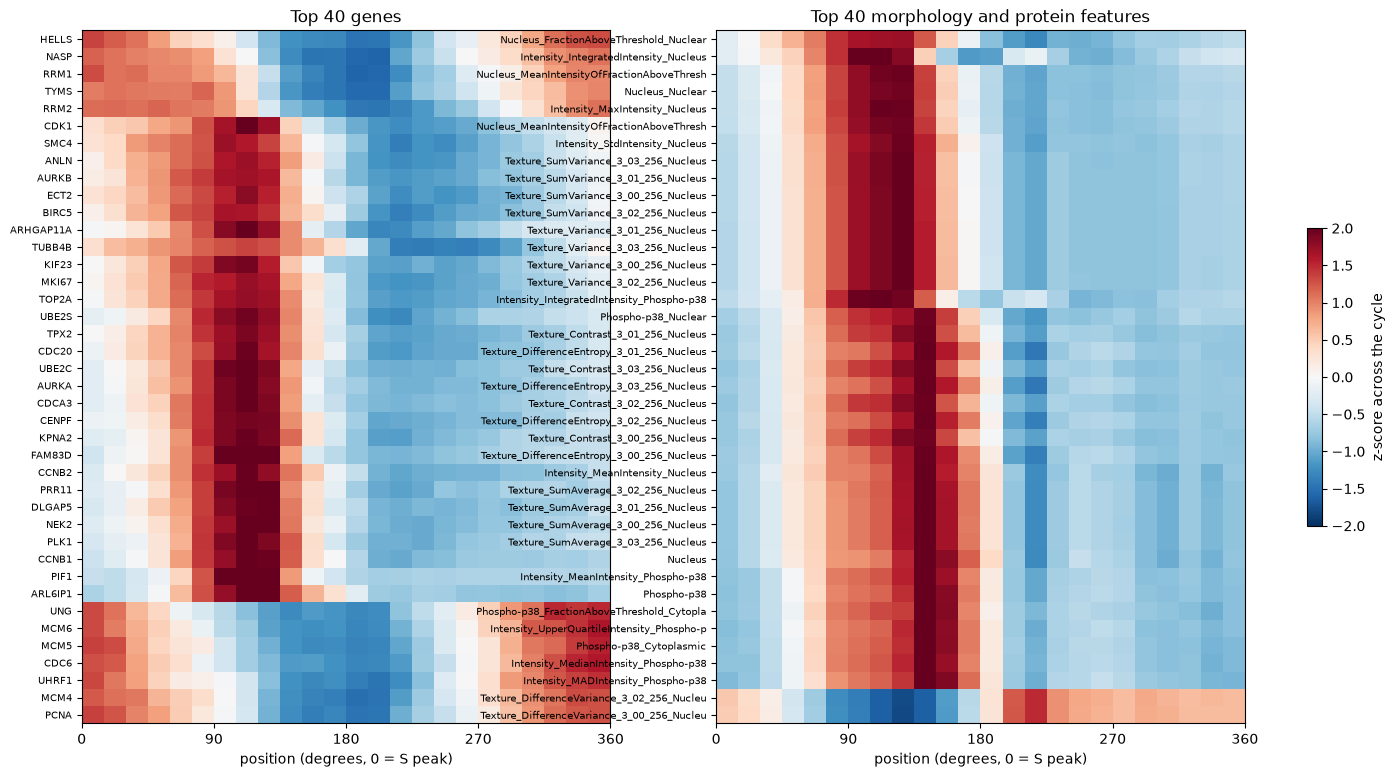

In [11]:
def heatmap(values, names, table, title, ax, n=40):
    top = table.head(n).sort_values("peak").index
    columns = pd.Index(names).get_indexer(top)
    bins_index = (np.degrees(shared["cycle_position"].values) // 15).astype(int)
    means = pd.DataFrame(centre(values[:, columns]), columns=top).groupby(bins_index).mean()
    scaled = (means - means.mean()) / means.std()
    image = ax.imshow(scaled.T, aspect="auto", cmap="RdBu_r", vmin=-2, vmax=2, extent=[0, 360, len(top), 0], interpolation="nearest")
    ax.set_yticks(np.arange(len(top)) + 0.5, [t[:42] for t in top], fontsize=7)
    ax.set_xticks(range(0, 361, 90))
    ax.set(xlabel="position (degrees, 0 = S peak)", title=title)
    return image


fig, axes = plt.subplots(1, 2, figsize=(16, 9))
heatmap(gene_values, gene_names, gene_table, "Top 40 genes", axes[0])
image = heatmap(feature_values, feature_names, feature_table, "Top 40 morphology and protein features", axes[1])
fig.colorbar(image, ax=axes, fraction=0.012, label="z-score across the cycle")
fig.savefig("figures/feature_heatmaps.png", dpi=130, bbox_inches="tight")
plt.show()

In [12]:
KNOCKOUTS = ["TGFBR2", "SMAD7", "IL1R1", "GSK3B", "CTNNB1", "OR1I1"]
target, condition = np.asarray(shared["Metadata_Perturbation"], dtype=str), np.asarray(shared["Metadata_Condition"], dtype=str)


def knn(values, y):
    return cross_val_score(KNeighborsClassifier(15), values, y, cv=5, scoring="balanced_accuracy").mean()


knn_scores, activity, energy = {}, {}, {}
for name, v in {k: views[k] for k in ["RNA PCA", "cycleVI z_other"]}.items():
    row = {"TNFa": knn(v, condition)}
    for ko in KNOCKOUTS:
        row[ko] = np.mean([knn(v[m], target[m]) for m in ((condition == c) & np.isin(target, [ko, "NTC"]) for c in ("baseline", "TNFa"))])
    knn_scores[name] = row
    a = view(v)
    a.obs_names = [str(i) for i in range(a.n_obs)]
    mt.io.stamp(a, resolution="object", feature_kind="embedding")
    mt.pp.annotate_controls(a, negcon=["NTC"])
    profiles = mt.tl.aggregate(a, by=("Metadata_Plate", "Metadata_Well", "Metadata_Guide"), func="mean")
    mt.tl.map(profiles, mode="activity", batch="Metadata_Condition", null_size=1000)
    activity[name] = profiles.uns["mantispy"]["map"].set_index("Metadata_Perturbation")["score"]
    within = a[a.obs["Metadata_Condition"] == "baseline"].copy()
    mt.tl.edistance(within, reference="negcon", n_permutations=200, max_reference=2000)
    energy[name] = within.uns["mantispy"]["edistance"].set_index("group")["distance"]
display(pd.DataFrame(knn_scores).T.round(3))
display(pd.DataFrame(activity).T.round(3))
pd.DataFrame(energy).T.round(4)

,TNFa,TGFBR2,SMAD7,IL1R1,GSK3B,CTNNB1,OR1I1
RNA PCA,0.837,0.537,0.504,0.503,0.512,0.626,0.5
cycleVI z_other,0.587,0.542,0.502,0.499,0.518,0.637,0.5


Metadata_Perturbation,CTNNB1,GSK3B,IL1R1,OR1I1,SMAD7,TGFBR2
RNA PCA,0.792,0.621,0.527,0.625,0.563,0.743
cycleVI z_other,0.933,0.651,0.579,0.619,0.591,0.715


group,CTNNB1,GSK3B,IL1R1,NTC,OR1I1,SMAD7,TGFBR2
RNA PCA,0.2951,0.0150,0.0080,-0.0014,-0.0026,0.0112,0.2176
cycleVI z_other,0.2006,0.0169,0.0038,0.0005,-0.0007,0.0044,0.0804


## Knockouts as readouts along the cycle

For each well, we compute the circular mean position and the share of cells in six sectors of the cycle for each knockout, and compare them with non-targeting cells in the same well. OR1I1 has no expected phenotype, so it shows the size of a difference expected by chance. Each guide is also tested on its own, because a real effect should appear in all four guides.

In [13]:
target_all, position_all = obs["target_gene"].astype(str).values, obs["cycle_position"].values
guide_all = obs["guide"].astype(str).values


def circular_shift(labels, ref_mask):
    rows = []
    for label in sorted(set(labels[~ref_mask]) - {"Undetermined"}):
        differences = []
        for well in np.unique(wells):
            a, b = position_all[(labels == label) & (wells == well)], position_all[ref_mask & (wells == well)]
            if len(a) >= 20:
                differences.append((stats.circmean(a) - stats.circmean(b) + np.pi) % (2 * np.pi) - np.pi)
        differences = np.degrees(differences)
        rows.append({"group": label, "wells": len(differences), "mean shift (degrees)": differences.mean(), "sd over wells": differences.std(ddof=1), "p": stats.ttest_1samp(differences, 0).pvalue})
    out = pd.DataFrame(rows).set_index("group")
    out = out.dropna(subset=["p"])
    out["q"] = stats.false_discovery_control(out["p"])
    return out


display(circular_shift(target_all, target_all == "NTC").round(4))
guide_shift = circular_shift(guide_all, target_all == "NTC")
guide_shift[guide_shift.index.str.startswith(("CTNNB1", "TGFBR2", "OR1I1"))].round(4)

,wells,mean shift (degrees),sd over wells,p,q
group,,,,,
CTNNB1,12,-71.6757,48.5163,0.0003,0.0020
GSK3B,12,3.8083,39.4247,0.7442,0.8930
IL1R1,12,-8.9906,46.0558,0.5129,0.7693
OR1I1,12,6.1628,20.6326,0.3230,0.7693
SMAD7,12,6.4956,32.7949,0.5068,0.7693
TGFBR2,12,3.0833,80.1626,0.8964,0.8964


,wells,mean shift (degrees),sd over wells,p,q
group,,,,,
CTNNB1_1,12,-60.1832,49.7170,0.0015,0.0346
CTNNB1_2,12,-65.0701,86.1255,0.0239,0.1836
CTNNB1_3,12,-18.9416,97.9593,0.5168,0.8775
CTNNB1_4,12,0.5801,91.3834,0.9828,0.9891
OR1I1_1,12,13.4082,45.8911,0.3332,0.8470
OR1I1_2,12,2.6407,28.1663,0.7514,0.9602
OR1I1_3,12,2.9305,39.0915,0.7999,0.9683
OR1I1_4,12,17.0387,30.1607,0.0762,0.3720
TGFBR2_1,12,46.3096,83.4656,0.0809,0.3720


In [14]:
sectors = pd.cut(position_all, np.linspace(0, 2 * np.pi, 7), include_lowest=True, labels=[f"{i * 60}-{(i + 1) * 60}" for i in range(6)]).astype(str)
fractions = pd.crosstab([wells, target_all], sectors, normalize="index")
rows = []
for ko in KNOCKOUTS:
    for sector in fractions.columns:
        a, b = fractions.xs(ko, level=1)[sector], fractions.xs("NTC", level=1)[sector]
        rows.append({"knockout": ko, "sector": sector, "difference": (a - b).mean(), "p": stats.ttest_rel(a, b).pvalue})
shift = pd.DataFrame(rows)
shift["q"] = stats.false_discovery_control(shift["p"])
display(shift.pivot(index="knockout", columns="sector", values="difference").round(4))
display(shift.sort_values("p").head(6).round(5))

well_condition = obs.groupby("Well", observed=True)["condition"].first().astype(str)
per_well = pd.crosstab(wells, sectors, normalize="index")
tnf = (per_well[well_condition.reindex(per_well.index).values == "TNFa"].mean() - per_well[well_condition.reindex(per_well.index).values == "baseline"].mean()).round(4)
print("TNFa minus baseline, share of cells per sector:", tnf.to_dict())

sector,0-60,120-180,180-240,240-300,300-360,60-120
knockout,,,,,,
CTNNB1,-0.0152,-0.0147,0.0326,0.0083,-0.0052,-0.0057
GSK3B,0.0014,0.0005,-0.0033,0.0006,-0.0015,0.0023
IL1R1,0.0008,-0.0027,-0.0001,0.0056,-0.0016,-0.0020
OR1I1,0.0020,-0.0003,0.0018,-0.0017,-0.0001,-0.0016
SMAD7,0.0049,-0.0045,0.0019,-0.0012,-0.0015,0.0004
TGFBR2,-0.0038,0.0112,0.0068,0.0086,-0.0136,-0.0093


,knockout,sector,difference,p,q
26,CTNNB1,180-240,0.03264,0.00000,0.00011
25,CTNNB1,120-180,-0.01474,0.00009,0.00156
24,CTNNB1,0-60,-0.01525,0.00022,0.00268
1,TGFBR2,120-180,0.01121,0.00561,0.05053
27,CTNNB1,240-300,0.00829,0.01601,0.11531
4,TGFBR2,300-360,-0.01356,0.05649,0.33895


TNFa minus baseline, share of cells per sector: {'0-60': -0.0044, '120-180': 0.0023, '180-240': 0.013, '240-300': 0.0008, '300-360': -0.006, '60-120': -0.0057}


A knockout with a strong RNA phenotype could move the RNA-based position without changing the cycle. So we repeat the test with measurements from imaging only: DNA content, cell area, and the position predicted from imaging by a model trained without any cells of that knockout.

In [15]:
rows = {}
for ko in ["CTNNB1", "TGFBR2", "OR1I1"]:
    train = target_all != ko
    fit = make_pipeline(StandardScaler(), Ridge(10)).fit(x[train][:, selected], np.column_stack([np.sin(position[train]), np.cos(position[train])]))
    guess = fit.predict(x[:, selected])
    guess = np.arctan2(guess[:, 0], guess[:, 1]) % (2 * np.pi)
    late = pd.Series((guess > np.radians(180)) & (guess < np.radians(240)))
    rna_late = pd.Series((position > np.radians(180)) & (position < np.radians(240)))
    frame_ko = pd.DataFrame({"well": wells, "target": target_all, "image": late.values, "rna": rna_late.values, "dna": obs["dna"].values, "area": np.log2(obs["cell_area"].values)})
    per_well = frame_ko[frame_ko["target"].isin([ko, "NTC"])].groupby(["well", "target"]).mean().unstack("target")
    row = {}
    for column, label in {"rna": "share in 180-240, RNA position", "image": "share in 180-240, imaging position", "dna": "DNA content (log2)", "area": "cell area (log2)"}.items():
        difference = per_well[column][ko] - per_well[column]["NTC"]
        row[f"{label}: difference"] = difference.mean()
        row[f"{label}: p"] = stats.ttest_1samp(difference, 0).pvalue
    rows[ko] = row
pd.DataFrame(rows).round(4)

,CTNNB1,TGFBR2,OR1I1
"share in 180-240, RNA position: difference",0.0326,0.0068,0.0018
"share in 180-240, RNA position: p",0.0000,0.3222,0.4796
"share in 180-240, imaging position: difference",-0.0073,0.0432,0.0010
"share in 180-240, imaging position: p",0.0049,0.0000,0.6770
DNA content (log2): difference,-0.0170,-0.0313,-0.0117
DNA content (log2): p,0.0195,0.0183,0.0381
cell area (log2): difference,0.2094,-0.1308,0.0040
cell area (log2): p,0.0000,0.0000,0.6019


## Do knockout effects depend on the position in the cycle?

We compare energy distances from non-targeting cells in six sectors of the cycle with `mt.tl.edistance` on the cell painting features. If an effect depends on the position, its distance should change across sectors while OR1I1 stays near zero.

In [16]:
paint_mask = selected & np.isin(modality, ["cell_paint", "shape"])
paint_pcs = PCA(30, random_state=0).fit_transform(x[:, paint_mask])
rows = {}
for sector in sorted(set(sectors), key=lambda s: int(s.split("-")[0])):
    m = (sectors == sector) & (obs["condition"].astype(str).values == "baseline")
    a = ad.AnnData(X=paint_pcs[m].astype(np.float32), obs=pd.DataFrame({"Metadata_Plate": "Cytos-MPS_TNFa", "Metadata_Well": wells[m], "Metadata_Perturbation": target_all[m], "Metadata_ImageID": wells[m], "Metadata_ObjectType": "cell", "Metadata_ObjectNumber": np.arange(m.sum())}, index=img.obs_names[m]))
    mt.io.stamp(a, resolution="object", feature_kind="embedding")
    mt.pp.annotate_controls(a, negcon=["NTC"])
    mt.tl.edistance(a, reference="negcon", n_permutations=100, max_reference=1000)
    rows[sector] = a.uns["mantispy"]["edistance"].set_index("group")["distance"]
pd.DataFrame(rows).round(4)

,0-60,60-120,120-180,180-240,240-300,300-360
group,,,,,,
CTNNB1,0.2796,0.2130,0.2200,0.4243,0.4334,0.2602
GSK3B,0.0074,0.0335,0.0045,0.0309,0.0008,0.0490
IL1R1,-0.0002,0.0265,-0.0011,0.0109,0.0008,0.0433
NTC,-0.0214,-0.0019,0.0187,0.0262,0.0092,-0.0001
OR1I1,-0.0046,0.0103,0.0004,0.0242,0.0041,0.0030
SMAD7,0.0387,0.0376,0.0065,0.0649,0.0238,0.0024
TGFBR2,0.4588,0.5267,0.5214,0.6233,0.5697,0.5909
